# <center> ISEL - AA </center>
## <center>Semestre 2024/25 </center>
###  <center> Trabalho Prático Nº1 </center>
###  <center> Pima Indians Diabetes Dataset </center>

Trabalho realizado por:
* João Ramos, numero <b> 50730 </b>
* Fábio Pestana, numero <b> 50756 </b>


<b> Turma: 51D </b> <br></br>
<b> Docente: Gonçalo Marques </b>

##  Introdução 

Este primeiro trabalho laboratorial tem como objetivo desenvolver um algoritmo capaz de determinar se os pacientes tem diabetes, segundo indicadores facilitados pelo *National Institute of Diabetes and Digestive and Kidney Diseases*.
Utilizou-se três classificadores binários e fez-se um estudos destes para comparar o seu desempenho.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import confusion_matrix, recall_score, f1_score, accuracy_score, precision_score, auc, roc_curve

## Leitura dos dados e chaves do dataset

In [2]:
fileDir = ''
fName='pimaDiabetes.p'

D=pickle.load(open(fileDir + fName,'rb'))

# Ver as chaves
print(D.keys())

dict_keys(['data', 'target', 'feature_names', 'DESCR'])


## Descrição e caracteristicas do dataset

In [3]:
print(f'Informações do dataset: \n\n{D["DESCR"]}')
print('\nCaracteristicas do dataset')

for nome in D['feature_names']:
    print(nome)

Informações do dataset: 

This dataset is originally from the National
Institute of Diabetes and Digestive and Kidney Diseases.
The objective of the dataset is to diagnostically predict
whether or not a patient has diabetes, based on certain
diagnostic measurements included in the dataset.
Several constraints were placed on the selection of these
instances from a larger database. In particular, all patients
here are females at least 21 years old of Pima Indian heritage.
The dataset contains information of 768 women from a population
near Phoenix, Arizona, USA. The outcome tested was Diabetes,
268 tested positive and 500 tested negative.

For more inforamtion:
Smith, J.W., Everhart, J.E., Dickson, W.C., Knowler, W.C., & Johannes, R.S.
(1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus.
In Proceedings of the Symposium on Computer Applications and Medical Care (pp. 261--265).
IEEE Computer Society Press.

Caracteristicas do dataset
Number of times pregnan

## Dados e classes do dataset

In [4]:
X = D['data']
y = D['target']

print('Shape da data:', X.shape)
print('Shape do target:', y.shape)

# Verifica-se quais as classes dos dados (0 e 1)
print('Classes do dataset:', np.unique(y)) 

Shape da data: (768, 8)
Shape do target: (768,)
Classes do dataset: [0 1]


## Verificação da organização do dataset

No código abaixo, é possível visualizar a ordem do dataset. A partir de ``y`` é possivel verificar as classificações de cada paciente (0 - negativo, não tem diabetes, 1 - positivo, paciente com diabetes). 

O gráfico abaixo demonstra que o dataset não está organizado por classes, logo não é necessário realizar um baralhamento adicional para evitar a ordenação por classes. Esta verificação é importante, pois a distribuição aleatória das classes garante que o modelo consiga aprender e distinguir os padrões de ambas as classes durante o seu treino. 

Caso a organização dos dados fosse sequencial, isto poderia causar problemas no treino dos modelos, pois com a divisão do dataset em treino e teste, o conjunto de treino poderia ficar com informação de apenas uma classe, prejudicando assim a sua capacidade de classificar corretamente a outra classe.

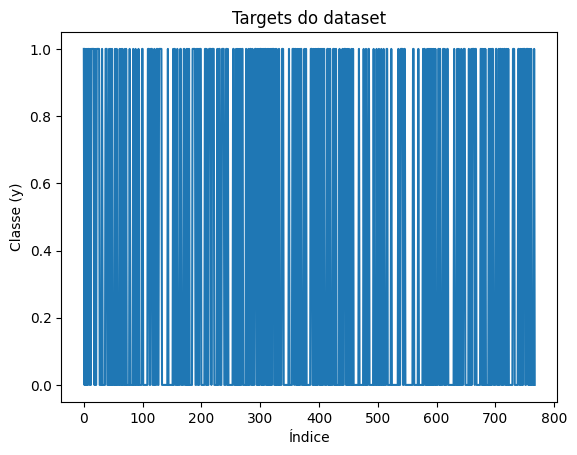

In [5]:
plt.title('Targets do dataset')
plt.xlabel("Índice")
plt.ylabel("Classe (y)")
plt.plot(y)
plt.show()

## Distribuição das Classes no dataset

No código abaixo, é possível calcular o número de casos positivos (pacientes com diabetes) e negativos (pacientes sem diabetes) no dataset, além de suas respectivas probabilidades. Esse trecho de código tem como objetivo analisar a distribuição do dataset (quantos pacientes têm e não têm diabetes) e identificar possíveis desbalanceamentos entre classes.

Os casos positivos correspondem às entradas em que ``y == 1``, enquanto os casos negativos correspondem às entradas em que ``y == 0``. A probabilidade é calculada dividindo o número de casos de cada classe pelo total de amostras.

In [6]:
casos_positivos = np.sum(y==1)
probabilidade_cp = np.round(casos_positivos/len(y), 2)

casos_negativos = np.sum(y==0)
probabilidade_cn = np.round(casos_negativos/len(y), 2)

print(f'Casos positivos:{casos_positivos}\nProbabilidade:{probabilidade_cp}')
print(f'\nCasos negativos:{casos_negativos}\nProbabilidade:{probabilidade_cn}')

Casos positivos:268
Probabilidade:0.35

Casos negativos:500
Probabilidade:0.65


## Separação do dataset para o treino e teste dos modelos

Nesta etapa, o dataset foi dividido em três conjuntos:

 * Conjunto de Treino (``Xt``): Este conjunto é utilizado para treinar o modelo, segundo combinações de hiperparâmetros. Através deste conjunto, o modelo aprende os padrões dos dados. A divisão de 50% dos dados para treino permite que o modelo tenha informações suficientes para aprender;

 * Conjunto de Validação (``Xv``): Após o treino, este conjunto é utilizado para avaliar o desempenho do modelo com uma combinação dos hiperparâmetros, para assim escolher-se qual a melhor combinação destes para melhorar o desempenho do modelo.
 A validação é importante porque permite que o modelo seja ajustado sem que se utilize o conjunto de teste, evitando que ele "aprenda" esses dados, o que prejudicaria a avaliação. A divisão de 20% para validação oferece dados suficientes para fazer ajustes ao modelo;

 * Conjunto de Teste (``Xf``): Este conjunto é utilizado para avaliar o desempenho final do modelo em dados nunca vistos, simulando assim a situação real, onde o modelo precisa fazer previsões sobre novos dados. A divisão de 30% permite que o modelo seja testado com dados suficientes para termos uma avaliação mais realista do modelo.

Em código, inicialmente são inicializadas duas variáveis: 
* ``percentagem_treino`` que indica a percentagem do dataset que será usada para o conjunto de treino (50%); 

* ``percentagem_validacao`` que indica a percentagem do dataset que será usada para o conjunto de validação (20%). 

De seguida, define-se o tamanho de cada conjunto (``treino`` e ``validacao``), teste como será composto pelos restantes 30% do dataset não é necessário calcular o seu tamanho. 

Utilizando a indexação, separa-se o conjunto de dados (``X``) e sua classificação (``y``) nos três conjuntos mencionados anteriormente (conjuntos de dados: ``Xt``, ``Xv``, ``Xf`` e  conjuntos das classes: ``yt``, ``yv``, ``yf``).

In [7]:
# Percentagens para cada conjunto de dados
# 50% dos dados para o conjunto de treino e 20% para o conjunto de validação
# Resto 30% para o conjunto de testes
percentagem_treino = 0.5
percentagem_validacao = 0.2

# Número de pacientes 
tamanho_data = X.shape[0]

# Define-se o número de amostras para os conjuntos
treino = int(tamanho_data * percentagem_treino)
validacao = treino + int(tamanho_data * percentagem_validacao)

# Divide-se X e y entre os três conjuntos: treino, validação e teste.
Xt = X[:treino] # 0 a treino-1
yt = y[:treino]

Xv = X[treino:validacao] # treino a validação-1
yv = y[treino:validacao]

Xf = X[validacao:] # validacao até ao fim de X
yf = y[validacao:]

# Prints para verificar a divisão dos conjuntos
print(f'Data de treino:{Xt.shape}. Target de treino:{yt.shape}')
print(f'Data de validacao:{Xv.shape}. Target de validacao:{yv.shape}')
print(f'Data de teste:{Xf.shape}. Target de teste:{yf.shape}')

Data de treino:(384, 8). Target de treino:(384,)
Data de validacao:(153, 8). Target de validacao:(153,)
Data de teste:(231, 8). Target de teste:(231,)


## Escolha dos hiperparâmetros dos classificadores binários.

Para o problema de determinar se uma pessoa tem ou não diabetes, o grupo escolheu os seguintes classificadores binários:

* **Random Forest** - foi escolhido por ser um classificador robusto e eficiente que lida bem com dados complexos, que pode ter interações não lineares entre as variáveis, como o caso do dataset pimaDiabetes(normalmente, problemas médicos tem interações não lineares entre as suas variáveis). 
O Random Forest combina várias árvores de decisão, o que melhora a capacidade do generalização do modelo, ou seja a partir dos dados que tem de treino, consegue obter métricas capazes de decidir outros casos desconhecidos;

* **Logistic Regression** - optou-se por este modelo devido à sua simplicidade e eficácia em problemas de classificação binária. Onde a partir das variáveis que recebe no dataset, ele cria um limiar de decisão que divide o espaço de amostras de forma a conseguir maximizar a separação entre as classes, com isto consegue indicar a probabilidade de um paciente ter ou não diabetes;

* **Support Vector Machine** - foi escolhido por sua capacidade de lidar com problemas de classificação complexos, especialmente quando as classes não são linearmente separáveis. O SVM é eficaz para dados de alta dimensão e pode encontrar a melhor margem de separação entre as classes.

Cada classificardor foi ajustado através da busca pelos melhores hiperparâmetros, para assim estes terem um melhor desempenho a classificar pacientes.

## Random Forest 

O Random Forest é um classificador baseado em um conjunto de árvores de decisão. Ele funciona criando várias árvores de decisão durante o treino e saindo com a média ou a moda das previsões dessas árvores, ou seja cada árvore de decisão classifica um dado, numa classe e a classe do dado que mais árvores "votaram" será a classificação atribuida a esses dados.

Cada árvore do conjunto de árvores de decisão é construída de maneira independente, utilizando uma amostra aleatória do conjunto de dados de treino e uma seleção aleatória das características.

Este modelo a partir da aleatoriedade garante a diversidade das árvores de decisão, pois irá possuir várias combinações de árvores de decisão que seguem diferentes caracteristicas do dataset. 

Este processo impede que o modelo se ajuste demais a um conjunto específico de dados, diminui o risco de overfitting e melhora a capacidade de generalização do modelo.


#### Hiperparâmetros ajustados:

Para otimizar o desempenho deste modelo, ajustamos os seguintes hiperparâmetros:

 * **Número de árvores:**
 
    Este parâmetro define o número de árvores que serão construídas na floresta.  <br>
    Valores testados: 50, 100, 200. <br><br>

 * **Profundidade máxima das árvores:**

   Este parâmetro controla a profundidade máxima das árvores de decisão.<br>
   Valores testados: None (sem limite), 10, 20. <br><br>

 * **Número mínimo de amostras necessárias para dividir um nó:**

   Este parâmetro determina o número mínimo de amostras necessárias para dividir um nó em uma árvore. <br>
   Valores testados: 2, 5, 10.


Em código, inicialmente são inicializadas as listas dos hiperparâmetros que serão testados, ``n_estimators_options`` (lista dos valores a testar para o número de árvores), ``max_depth_options`` (lista dos valores a testar para a profundidade máxima das árvores de decisão) e ``min_samples_split_options`` (lista dos valores a testar para o número mínimo de amostras necessárias para dividir um nó em uma árvore).

De seguida, desenvolveu-se o método ``rf_hiperparametros`` que recebe as várias listas anteriores e os conjuntos de treino e validação. Este método tem como objetivo realizar a busca pelos melhores hiperparâmetros para o modelo Random Forest, para isso percorre as várias listas que recebe, e instância um modelo ``RandomForestClassifier`` para cada combinação dos hiperparâmetros. 

Para cada modelo, calcula-se a precisão do modelo se a precisão calculada for maior do que a melhor precisão guardada (``best_score_rf``), guarda-se os valores da combinação dos hiperparâmetros (``best_params_rf``) e atualiza-se a melhor precisão guardada.

In [8]:
n_estimators_options = [50, 100, 200]
max_depth_options = [None, 10, 20]
min_samples_split_options = [2, 5, 10]

def rf_hiperparametros(n_estimators, max_depths, min_samples_splits, Xt, yt, Xv, yv):
    """
    Método que realiza a busca pelos melhores hiperparâmetros para o modelo Random Forest.

    Args:
        - n_estimators - Lista dos valores a testar para o número de árvores.
        - max_depths - Lista dos valores a testar para a profundidade máxima das árvores de decisão
        - min_samples_splits - Lista dos valores a testar para o número mínimo de amostras necessárias para dividir um nó em uma árvore
        - Xt - Conjunto de dados de treino.
        - yt - Classificações do conjunto de treino.
        - Xv - Conjunto de dados de validação.
        - yv - Classificações do conjunto de validação.

    Returns:
        - best_params_rf - Melhor combinação de hiperparâmetros encontrada.
        - best_score_rf - Melhor score obtido no conjunto de validação.
    """
    best_score_rf = 0
    best_params_rf = {}

    for n in n_estimators:
        for depth in max_depths:
            for split in min_samples_splits:

                rf = RandomForestClassifier(n_estimators=n, max_depth=depth, min_samples_split=split, random_state=42)
                rf.fit(Xt, yt)
                
                score = rf.score(Xv, yv)
                
                # Estratégia de seleção de hiperparâmetros:
                # Priorizar o melhor score
                if score > best_score_rf:
                    best_score_rf = score
                    best_params_rf = {'n_estimators': n, 'max_depth': depth, 'min_samples_split': split}
                    
    return best_params_rf, best_score_rf


best_params_rf, best_score_rf = rf_hiperparametros(n_estimators_options, max_depth_options, min_samples_split_options, Xt, yt, Xv, yv)

print("Melhores hiperparâmetros para Random Forest com base no score:", best_params_rf)
print("Score correspondente:", round(best_score_rf, 3))

Melhores hiperparâmetros para Random Forest com base no score: {'n_estimators': 200, 'max_depth': None, 'min_samples_split': 10}
Score correspondente: 0.824


## Logistic Regression


A Logistic Regression é um modelo linear simples que é eficiente para tarefas de classificação binária. Ele estima a probabilidade de uma classe dada uma combinação linear das variáveis de entrada, utilizando uma função logística para mapear as previsões. 

Tal como já foi referido anteriormente, este modelo cria um limiar de decisão que divide o espaço de amostras para assim conseguir distinguir as classes.

#### Hiperparâmetros ajustados:

Para otimizar o desempenho deste modelo, ajustamos os seguintes hiperparâmetros:

 * **Parâmetro de regularização:**

   O valor de C afeta diretamente a capacidade do modelo de se ajustar aos dados de treino, ou seja, controla como o modelo é regulado, um valor grande deste valor pode levar a overfitting.<br>
   Valores testados: 0.01, 0.1, 1, 10, 100.<br><br>

 * **Algoritmo de otimização:**
 
   Este valor específica o algoritmo utilizado para otimizar a função de custo, também determina como os parâmetros do modelo são ajustados durante o treino.<br>
   Valores testados: 'lbfgs', 'liblinear'.



Em código, inicialmente são inicializadas as listas dos hiperparâmetros que serão testados, ``C_options`` (lista dos valores a testar para o parâmetro de regularização, C) e ``solver_options`` (lista dos valores a testar para o algoritmo de otimização).

De seguida, desenvolveu-se o método ``lr_hiperparametros`` que recebe as várias listas anteriores e os conjuntos de treino e validação. Este método tem como objetivo realizar a busca pelos melhores hiperparâmetros para o modelo Logistic Regression, para isso percorre as várias listas que recebe, e instância um modelo ``LogisticRegression`` para cada combinação dos hiperparâmetros. Para cada modelo, calcula-se a precisão do modelo se a precisão calculada for maior do que a melhor precisão guardada (``best_score_lg``), guarda-se os valores da combinação dos hiperparâmetros (``best_params_lg``) e atualiza-se a melhor precisão guardada.

In [9]:
C_options = [0.01, 0.1, 1, 10, 100]
solver_options = ['lbfgs', 'liblinear']

def lr_hiperparametros(Cs, solvers, Xt, yt, Xv, yv):
    """
    Método que realiza a busca pelos melhores hiperparâmetros para o modelo Logistic Regression.

    Args:
        - Cs - Lista dos valores a testar para o parâmetro de regularização.
        - solvers - Lista dos valores a testar para o algoritmo de otimização.
        - Xt - Conjunto de dados de treino.
        - yt - Classificações do conjunto de treino.
        - Xv - Conjunto de dados de validação.
        - yv - Classificações do conjunto de validação.

    Returns:
        - best_params_lg - Melhor combinação de hiperparâmetros encontrada.
        - best_score_lg - Melhor score obtido no conjunto de validação.
    """
    best_score_lg = 0
    best_params_lg = {}

    for C in Cs:
        for s in solvers:
            lr = LogisticRegression(C=C, solver=s, max_iter=1000, random_state=42)
            lr.fit(Xt, yt)
            
            score = lr.score(Xv, yv)
                        
            if score > best_score_lg:
                best_score_lg = score
                best_params_lg = {'C': C, 'solver': s}

    return best_params_lg, best_score_lg
        
best_params_lg, best_score_lg = lr_hiperparametros(C_options, solver_options, Xt, yt, Xv, yv)

print("Melhores hiperparâmetros para Logistic Regression com base no score:", best_params_lg)
print("Score correspondente:", round(best_score_lg, 3))

Melhores hiperparâmetros para Logistic Regression com base no score: {'C': 0.01, 'solver': 'lbfgs'}
Score correspondente: 0.824


## Support Vector Machine (SVM)

O SVM é um classificador conhecido pela sua eficiência em problemas de classificação de alta dimensão e pela sua capacidade de lidar com problemas de classificação como as classes não serem linearmente separáveis.

Este classificador tem como objetivo encontrar um hiperplano de decisão que separe o espaço de amostras, maximizando a margem entre as diferentes classes.  

#### Hiperparâmetros ajustados:

Para otimizar o desempenho deste modelo, ajustamos os seguintes hiperparâmetros:

 * **Parâmetro de regularização:**

   O valor de C afeta diretamente a capacidade do modelo de se ajustar aos dados de treino, ou seja, controla como o modelo é regulado, um valor grande deste valor pode levar a overfitting.<br>
   Valores testados: 0.1, 1, 10.<br><br>

 * **Kernel:**
 
   O kernel especifica a função que transforma os dados para uma forma onde a separação das classes se torna mais fácil. Por exemplo, quando se utiliza o Radial Basis Function (rbf), este kernel mapeia os dados para dimensões superiores, permitindo capturar fronteiras de decisão não lineares. <br>
   Valores testados: 'linear', 'rbf', 'sigmoid'.<br><br>

 * **Gamma:**
 
   O parâmetro gamma controla a influência de cada ponto dos dados, ajudando a definir a forma do limite de decisão. <br>
   Valores testados: 'scale' (valor automático baseado nas variáveis) e 'auto' (usa 1/n_features).

Em código, inicialmente são inicializadas as listas dos hiperparâmetros que serão testados, ``C_options`` (lista dos valores a testar para o parâmetro de regularização, C), ``kernel_options`` (lista de tipos de kernel a serem testados) e ``gamma_options`` (lista de valores para o parâmetro gamma).

De seguida, desenvolveu-se o método ``svm_hiperparametros`` que recebe as várias listas anteriores e os conjuntos de treino e validação. Este método tem como objetivo realizar a busca pelos melhores hiperparâmetros para o modelo Support Vector Machine, para isso percorre as várias listas que recebe, e instância um modelo ``SVC`` para cada combinação dos hiperparâmetros. Para cada modelo, calcula-se a precisão do modelo se a precisão calculada for maior do que a melhor precisão guardada (``best_score_svm``), guarda-se os valores da combinação dos hiperparâmetros (``best_params_svm``) e atualiza-se a melhor precisão guardada.

In [10]:
C_options = [0.1, 1, 10]
kernel_options = ['linear', 'rbf', 'sigmoid']
gamma_options = ['scale', 'auto']

def svm_hiperparametros(Cs, kernels, gammas, Xt, yt, Xv, yv):
    """
    Método que realiza a busca pelos melhores hiperparâmetros para o modelo Support Vector Machine.

    Args:
        - Cs - Lista dos valores a testar para o parâmetro de regularização.
        - kernels - Lista de tipos de kernel a serem testados.
        - gammas - lista de valores para o parâmetro gamma.
        - Xt - Conjunto de dados de treino.
        - yt - Classificações do conjunto de treino.
        - Xv - Conjunto de dados de validação.
        - yv - Classificações do conjunto de validação.

    Returns:
        - best_params_svm - Melhor combinação de hiperparâmetros encontrada.
        - best_score_svm - Melhor score obtido no conjunto de validação.
    """
    best_score_svm = 0
    best_params_svm = {}

    for C in Cs:
        for kernel in kernels:
            for gamma in gammas:

                svm = SVC(C=C, kernel=kernel, gamma=gamma, random_state=42)
                svm.fit(Xt, yt)
                
                score = svm.score(Xv, yv)
            
                if score > best_score_svm:
                    best_score_svm = score
                    best_params_svm = {'C': C, 'kernel': kernel, 'gamma': gamma}

    return best_params_svm, best_score_svm

best_params_svm, best_score_svm = svm_hiperparametros(C_options, kernel_options, gamma_options, Xt, yt, Xv, yv)

print("Melhores hiperparâmetros para SVM com base no Score:", best_params_svm)
print("Score correspondente:", round(best_score_svm, 3))

Melhores hiperparâmetros para SVM com base no Score: {'C': 1, 'kernel': 'linear', 'gamma': 'scale'}
Score correspondente: 0.824


## Avaliação dos Modelos e Comparação de Desempenho

Após descobrir-se os melhores hiperparâmetros para os três classificadores, instânciou-se os classificadores com os seus hiperparêmetros para assim estes serem treinados com o conjunto completo de treino (treino + validação) e testados com o conjunto de testes. <br>
Junta-se o conjunto de treino com o da validação, pois o objetivo de conjunto de validação já foi cumprido (servir como conjunto de teste para se descobrir os hiperparêmetros), logo este pode-se juntar com o conjunto de treino para assim os classificadores serem treinados com a maior quantidade possível de dados (70% do dataset original).

Para juntar os conjuntos de treino e validação, é necessário utilizar o método ``np.concatenate``, onde junta-se ``Xt`` com ``Xv`` e ``yt`` com ``yv``. De seguida, utiliza-se o método ``evaluate_model`` para treinar os classificadores com ``Xtreino`` e ``ytreino``, e testá-los com ``Xf``.

Após os testes, calculou-se as seguintes métricas de desempenho para se conseguir analisar os modelos:

 * Matriz de Confusão: Mostra o desempenho detalhado do modelo em termos de verdadeiros positivos (TP), verdadeiros negativos (TN), falsos positivos (FP) e falsos negativos (FN).<br>

$$
\text{Matriz de Confusão} =\begin{bmatrix}
TN & FP \\
FN & TP
\end{bmatrix}
$$
<br>

 * Probabilidade total de acertos: Proporção de classificações corretas do modelo em relação ao total.<br>

$$ 
\text{Probabilidade total de acertos} = \frac{TP + TN}{TP + TN + FP + FN} 
$$ 
<br>

 * Precisão: Proporção de classificações positivas corretas. <br>

$$
\text{Precisão} = \frac{TP}{TP + FP}
$$
<br>

 * Recall: Proporção dos positivos identificados corretamente. <br>

$$
\text{Recall} = \frac{TP}{TP + FN}
$$
 <br>

 * F-Score: Média harmônica entre precisão e recall. <br>

$$
\text{F-score} = 2 \cdot \frac{\text{Precisão} \cdot \text{Recall}}{\text{Precisão} + \text{Recall}}
$$


### Comparação Gráfica

Para facilitar a visualização e comparação dos resultados de cada modelo, para as métricas anteriores, fez-se um gráfico de barras com as métricas (probabilidade total de acertos, precisão, recall e f-Score).

(537, 8)
(537,)
Resultados para RandomForestClassifier:
Probabilidade total de acertos: 0.7965
Precisão: 0.7667
Recall: 0.5823
F-score: 0.6619
Matriz de Confusão:
[[138  14]
 [ 33  46]]

Resultados para LogisticRegression:
Probabilidade total de acertos: 0.7879
Precisão: 0.7500
Recall: 0.5696
F-score: 0.6475
Matriz de Confusão:
[[137  15]
 [ 34  45]]

Resultados para SVC:
Probabilidade total de acertos: 0.7749
Precisão: 0.7368
Recall: 0.5316
F-score: 0.6176
Matriz de Confusão:
[[137  15]
 [ 37  42]]



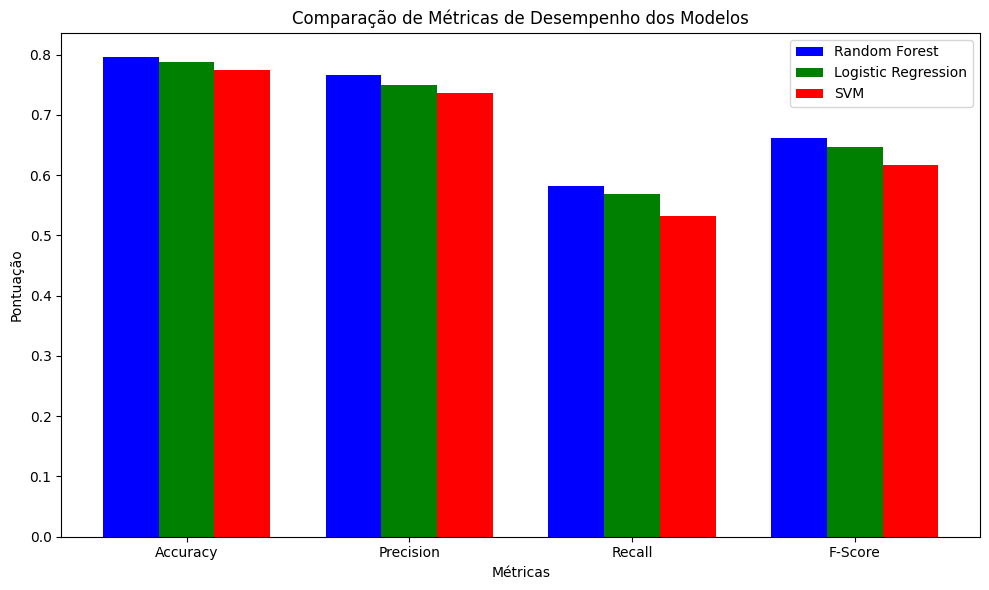

In [11]:
# Concatonou-se o conjunto de treino (Xt, yt) e o de
# validação (Xv, yv) para formar o conjunto de treino completo (Xtreino, ytreino)
Xtreino = np.concatenate((Xt, Xv), axis=0)
ytreino = np.concatenate((yt, yv), axis=0)

# Prints para verificar a concatenação dos conjuntos
print(Xtreino.shape)
print(ytreino.shape)

# Inicialização dos classificadores com os hiperparâmetros encontrados anteriormente
rf = RandomForestClassifier(n_estimators=best_params_rf['n_estimators'], 
                            max_depth=best_params_rf['max_depth'], 
                            min_samples_split=best_params_rf['min_samples_split'],
                            random_state=42)

lr = LogisticRegression(C=best_params_lg['C'], 
                        solver=best_params_lg['solver'], 
                        max_iter=1000, 
                        random_state=42)

svm = SVC(C=best_params_svm['C'], 
          kernel=best_params_svm['kernel'], 
          gamma=best_params_svm['gamma'], 
          random_state=42)


def evaluate_model(model, X_test, y_test, X_train, y_train):
    """
    Método que treina e avalia o desempenho de um modelo segundo os
    conjunto de treino e testes que recebe.

    Args:
        - model - classificador a ser treinado e testado
        - X_test - Conjunto de dados de teste
        - y_test - Classificações do conjunto de teste.
        - X_train - Conjunto de dados de treino. 
        - y_train - Classificações do conjunto de treino.

    Returns:
        - [accuracy, precision, recall, f1] - Lista com as métricas .
        - cm - Matriz de confusão.
    """

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    # Cálculo das métricas de desempenho
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred) 
    f1 = f1_score(y_test, y_pred) 
    cm = confusion_matrix(y_test, y_pred)

    # Extração de valores da matriz de confusão
    TN = cm[0][0] # Verdadeiros Negativos
    TP = cm[1][1] # Verdadeiros Positivos

    # Soma dos elementos da matriz de confusão
    soma = np.sum(cm)

    # Calculo da probabilidade total de acertos
    accuracy = (TP + TN) / soma
    
    # Prints dos resultados das métricas do modelo
    print(f"Resultados para {model.__class__.__name__}:")
    print(f"Probabilidade total de acertos: {accuracy:.4f}")
    print(f"Precisão: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F-score: {f1:.4f}")
    print(f"Matriz de Confusão:\n{cm}\n")
    
    return [accuracy, precision, recall, f1], cm

RandomForestResults , rf_conf_matrix = evaluate_model(rf, Xf, yf, Xtreino, ytreino)
LogisticRegressionResults, lg_conf_matrix = evaluate_model(lr, Xf, yf, Xtreino, ytreino)
SvmResults, svm_conf_matrix = evaluate_model(svm, Xf, yf, Xtreino, ytreino)


# Comparação gráfica dos resultados
metrics = ['Accuracy', 'Precision', 'Recall', 'F-Score']

bar_width = 0.25
index = np.arange(len(metrics))

plt.figure(figsize=(10, 6))
plt.bar(index, RandomForestResults, bar_width, label='Random Forest', color='blue')
plt.bar(index + bar_width, LogisticRegressionResults, bar_width, label='Logistic Regression', color='green')
plt.bar(index + 2 * bar_width, SvmResults, bar_width, label='SVM', color='red')

plt.xlabel('Métricas')
plt.ylabel('Pontuação')
plt.title('Comparação de Métricas de Desempenho dos Modelos')
plt.xticks(index + bar_width, metrics)
plt.legend()

plt.tight_layout()
plt.show()

> Comentário:

* **Random Forest** apresentou o melhor desempenho geral, com uma probabilidade total de acertos de 79.65%, uma boa precisão (76.67%) e recall de 58.23%. Embora tenha deixado de identificar alguns casos de diabetes, ele destacou-se em comparação aos outros modelos.

* **Logistic Regression** teve um desempenho muito próximo ao do Random Forest, com uma probabilidade total de acertos um pouco menor (78.79%) e um recall mais baixo (56.96%). A sua precisão foi boa (75%), mas não tão alta quanto a do Random Forest.

* **Support Vector Machine** teve o pior desempenho, com a menor probabilidade total de acertos (77.49%) e recall (53.16%). Apesar de apresentar uma boa precisão (73.68%).

Em resumo, os três classificadores apresentaram resultados semelhantes, com o Random Forest sendo o modelo mais eficaz, enquanto a SVM teve o desempenho mais fraco.  É importante destacar que, nos três casos, o recall está bastante baixo, no intervalo entre 50% e 60%, o que é uma preocupação em contextos de diagnóstico médico. Isto ocorre porque o número de Falsos Negativos e Verdadeiros Positivos está muito próximo, ou seja, os três modelos estão classificando de forma imprecisa cerca de 10 pacientes com diabetes, 5 como diabéticos e 5 como não diabéticos.

Em diagnósticos médicos, é fundamental evitar os Falsos Negativos, pois isso pode levar à falha na identificação de um problema de saúde real, o que pode resultar em agravamento do estado do paciente. Portanto, nos três modelos, seria necessário calibrá-los para aumentar o valor do recall, reduzindo assim o número de falsos negativos e melhorando a capacidade de detecção de casos positivos.

--------------------------------------

## Calibração dos Modelos

A calibração de um classificador é um processo importante quando se deseja ajustar o limiar de decisão, especialmente em situações onde se deseja controlar a quantidade de falsos negativos (falhas de deteção de diabetes). <br>

Para ajustar o limiar de decisão, é necessário obter a função de decisão do classificador. Dependendo do modelo de classificação do ``scikit-learn``, pode se utilizar uma dos seguintes métodos:

 * ``predict_proba``: retorna as probabilidades previstas de cada amostra pertencer a cada classe, o modelo aplica sobre esta função o limiar de decisão de 0.5, para classificar os dados. Os classificadores Random Forest e Logistic Regression têm este método, o SVM não.

 * ``decision_function``: retorna os valores da função de decisão que o modelo usa para classificar as amostras, o modelo aplica sobre esta função o limiar de decisão de 0, para classificar os dados. O classificador SVM tem este método.

De seguida, para determinar o melhor limiar de decisão, utiliza-se o método ``limiar_modelo`` que ajusta o limiar de decisão do modelo para alcançar uma taxa de verdadeiros positivos (TPR) de 90%. Este método utiliza a função ``roc_curve``, que calcula a curva de desempenho do modelo.
A partir desta, encontra-se o limiar que garante o valor mínimo de recall desejado (para os três classificadores o valor escolhido foi um recall de 90%).

Por fim, aplica-se o limiar calculado anteriormente no método ``calibracao``, que recalcula as previsões do modelo. As probabilidades maiores ou iguais ao limiar calculado são classificadas como positivas (1) e as menores como negativas (0).


In [12]:
def calibracao(model, X_test, y_test, limiar): 
    """
    Método que recalcula as previsões do modelo, segundo o limiar recebido. 
    As probabilidades maiores ou iguais ao limiar recebido são classificadas 
    como positivas (paciente com diabetes) e as menores como negativas (paciente 
    sem diabetes).

    Args:
         - model - Modelo a calibrar.
         - X_test - Conjunto de dados de teste.
         - y_test - Classificações do conjunto de teste.
         - limiar - Limiar de decisão para ajustar a classificação.

    Returns:
         - [score, precision, recall, f-score] - Uma lista com métricas de desempenho do classificador.
         - conf - Matriz de confusão.
         - model_probs - Função de decisão do classificador.
    """

    # Se o modelo tiver o método predict_proba, 
    # utiliza-o para obter as probabilidades de cada classe.
    # Se não usa a função de decisão.
    if hasattr(model, "predict_proba"):
        model_probs = model.predict_proba(X_test)
        # Utiliza-se as probabilidades da classe positiva (1)
        model_probs = model_probs[:, 1]
    else:
        model_probs = model.decision_function(X_test)
        #print(f"O {model.__class__.__name__} nao tem o metodo predict_proba.")
        #print(f"O intervalo dos valores da função de decisão são os seguintes:")
        #print(f"  Valor mínimo: {model_probs.min(): .4f}")
        #print(f"  Valor máximo: {model_probs.max(): .4f}")

    # Aplica-se o novo limiar de decisão do modelo.
    y_calib = (model_probs>=limiar).astype(int)

    conf = confusion_matrix(y_test, y_calib)

    # Calcula as métricas do desempenho
    score = accuracy_score(y_test, y_calib)
    precision = precision_score(y_test, y_calib)
    recall = recall_score(y_test, y_calib)
    f1 = f1_score(y_test, y_calib)

    print(f"Resultados para {model.__class__.__name__}, com o limiar {limiar}:")
    print(f"Probabilidade total de acertos: {score:.4f}")
    print(f"Precisão: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F-score: {f1:.4f}")
    print(f"Matriz de Confusão:\n{conf}\n")

    return [score, precision, recall, f1], conf, model_probs


def limiar_modelo(modelo, limiar_tpr, X_teste, y_teste):
    """
    Método que determina o limiar que otimiza recall de um modelo (segundo o limiar_tpr recebido).

    Args:
        - model - Modelo a calibrar.
        - limiar_tpr - Limiar mínimo desejado para a taxa de verdadeiros positivos (TPR).
        - X_teste - Conjunto de dados de teste.
        - y_teste - Classificações do conjunto de teste.

    Returns:
        - limiares[i] - Limiar de decisão que alcança o recall desejado.
    """

    # Se o modelo tiver o método predict_proba, 
    # utiliza-o para obter as probabilidades de cada classe.
    # Se não usa a função de decisão.
    if hasattr(modelo, "predict_proba"):
        model_probs = modelo.predict_proba(X_teste)
        y_pred_proba = model_probs[:, 1]
    else:
        y_pred_proba = modelo.decision_function(X_teste)
    
    # Calculo da curva ROC para obter a taxa de verdadeiros positivos
    _, tpr, limiares = roc_curve(y_teste, y_pred_proba)
        
    # Procura-se o índice do limiar que atinge o TPR desejado.
    i = np.argmax(tpr >= limiar_tpr) 
    
    return limiares[i]


limiar_dos_modelos = 0.9

limiar_rf = limiar_modelo(rf, limiar_dos_modelos, Xf, yf)
rf_calib_results, rf_calib_conf_matrix, y_pred_rf = calibracao(rf, Xf, yf, limiar_rf)

limiar_lr = limiar_modelo(lr, limiar_dos_modelos, Xf, yf)
lr_calib_results, lr_calib_conf_matrix, y_pred_lr = calibracao(lr, Xf, yf, limiar_lr)

limiar_svm = limiar_modelo(svm, limiar_dos_modelos, Xf, yf)
svm_calib_results, svm_calib_conf_matrix, y_pred_svm = calibracao(svm, Xf, yf, limiar_svm)

Resultados para RandomForestClassifier, com o limiar 0.25818617697661805:
Probabilidade total de acertos: 0.7229
Precisão: 0.5581
Recall: 0.9114
F-score: 0.6923
Matriz de Confusão:
[[95 57]
 [ 7 72]]

Resultados para LogisticRegression, com o limiar 0.2703175394976814:
Probabilidade total de acertos: 0.7532
Precisão: 0.5902
Recall: 0.9114
F-score: 0.7164
Matriz de Confusão:
[[102  50]
 [  7  72]]

Resultados para SVC, com o limiar -0.987410477528079:
Probabilidade total de acertos: 0.7532
Precisão: 0.5887
Recall: 0.9241
F-score: 0.7192
Matriz de Confusão:
[[101  51]
 [  6  73]]



> Comentário:

* **Random Forest** teve o pior desempenho, com uma probabilidade total de acertos de 72.29% e precisão de 55.81%, no entanto, ele teve um ótimo recall de 91.14%. Este alto recall indica que o modelo foi muito eficaz em classificar os casos de pacientes com diabetes, mas entre os três classificadores ele foi aquele com maior número de falsos alarmes.

* **Logistic Regression** teve um desempenho muito próximo ao do Support Vector Machine, com uma probabilidade total de acertos de 75.32% e um recall igual ao Random Forest 91.14%. Com o aumento do recall a sua precisão desceu para 59.02%, sendo esta a melhor entre os três classificadores. 

* **Support Vector Machine** apresentou o melhor desempenho geral, com uma probabilidade total de acertos igual ao Logistic Regression e com o melhor recall dos três classificadores de 92.41%. A precisão deste desceu para 58.87%, no entanto teve o f-score mais alto de 71.92% demonstrando ser o modelo mais balanceado dos três, após a calibração.

Em resumo, os três classificadores apresentaram resultados semelhantes nas métricas de desempenho, com o Random Forest sendo o modelo com os piores valores, enquanto a SVM com os melhores. O Support Vector Machine teve o melhor recall, o que é crucial em contextos médicos, pois indica que mais casos de pacientes com diabetes foram corretamente identificados.

----------------------------------------------------------------

## Comparação dos Modelos Calibrados vs Não Calibrados

A visualização das métricas de desempenho para os três modelos (Random Forest, Logistic Regression, e SVM) permite observar o impacto da calibração nos resultados. O código abaixo gera gráficos de barra para comparar o desempenho dos modelos antes e depois da calibração, focando nas seguintes métricas de desempenho: probabilidade total de acertos, precisão, recall e f-Score.

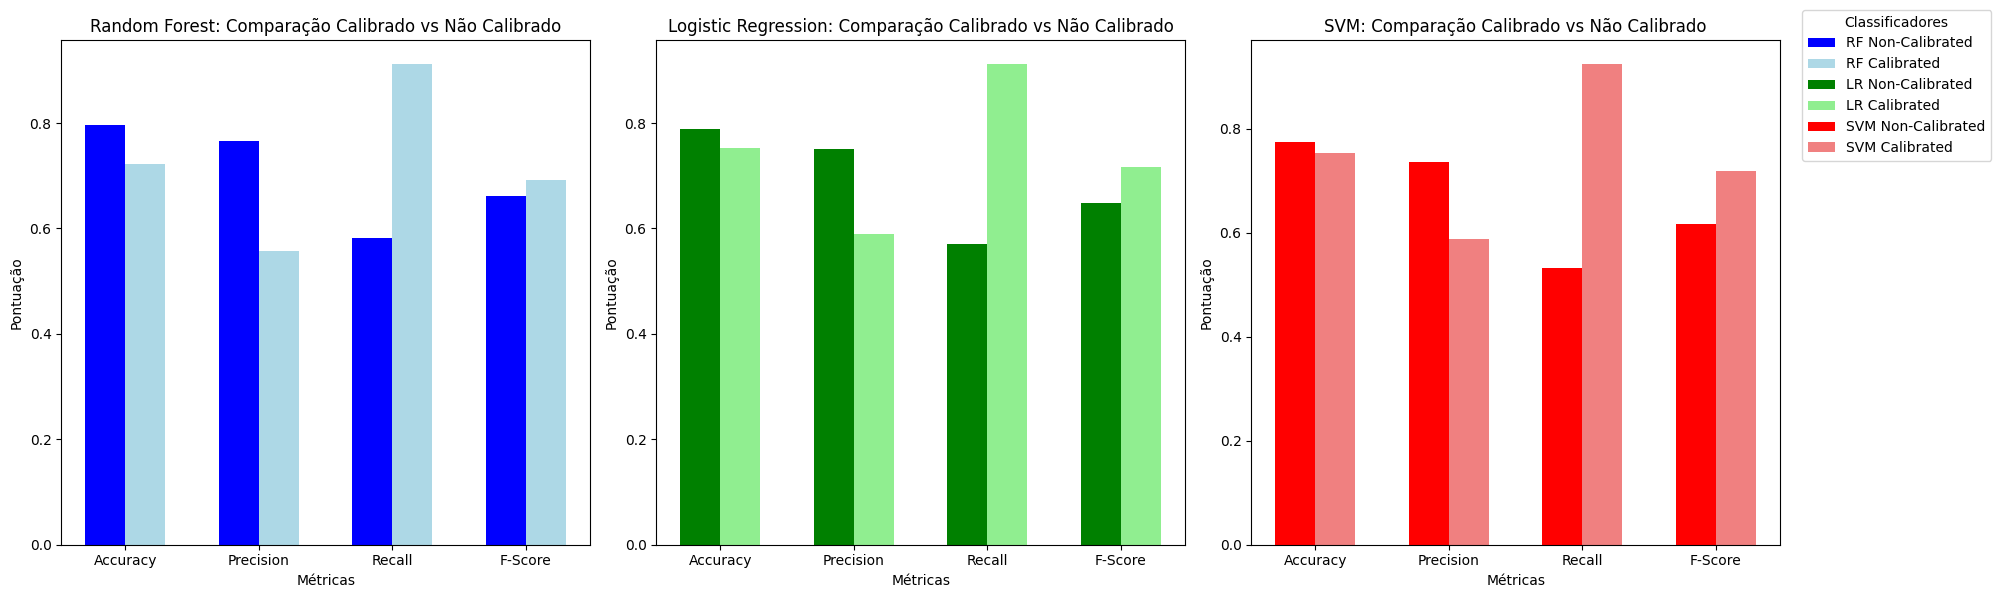

In [13]:
# Criação de uma figura com 3 subplots lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
bar_width = 0.3

def barras (axes, title, ind, width, metrics, score1, score2, label1, label2, color1, color2):
    '''
    Método que cria um gráfico de barras para comparação entre classificadores.

    Args:
        - axes - Subplots do gráfico onde as barras serão desenhadas.
        - title - Título do gráfico.
        - ind - Indicam onde as barras serão posicionadas no eixo das abscissas.
        - width - Largura das barras.
        - metrics - Métricas a serem exibidas no eixo X (probabilidade total de acertos, precisão, recall e f-Score).
        - score1 - Valores das métricas para o primeiro classificador.
        - score2 - Valores das métricas para o segundo classificador.
        - label1 - Legenda para o primeiro classificador.
        - label2 - Legenda para o segundo classificador.
        - color1 - Cor das barras do primeiro classificador.
        - color2 - Cor das barras do segundo classificador.

    Returns:
        - bar1 - Barra criada para o primeiro classificador.
        - bar2 - Barra criada para o segundo classificador.
    '''
    bar1 = axes.bar(ind, score1, bar_width, label=label1, color=color1)
    bar2 = axes.bar(ind + width, score2, bar_width, label=label2, color=color2)

    axes.set_xlabel('Métricas')
    axes.set_ylabel('Pontuação')
    axes.set_title(title)
    axes.set_xticks(ind + width / 2)  # Posiciona-se as marcas no eixo das abcissas no centro das barras
    axes.set_xticklabels(metrics)

    return bar1, bar2

title1='Random Forest: Comparação Calibrado vs Não Calibrado'
label1 = 'RF Non-Calibrated'
label2 = 'RF Calibrated'

bars_rf_non_calib, bars_rf_calib = barras(axes[0], title1, index, bar_width, metrics,RandomForestResults, rf_calib_results, label1, label2, 'blue', 'lightblue')

title1='Logistic Regression: Comparação Calibrado vs Não Calibrado'
label1 = 'LR Non-Calibrated'
label2 = 'LR Calibrated'
bars_lr_non_calib, bars_lr_calib = barras(axes[1], title1, index, bar_width, metrics,LogisticRegressionResults, lr_calib_results, label1, label2, 'green', 'lightgreen')

title1='SVM: Comparação Calibrado vs Não Calibrado'
label1 = 'SVM Non-Calibrated'
label2 = 'SVM Calibrated'
bars_svm_non_calib, bars_svm_calib = barras(axes[2], title1, index, bar_width, metrics,SvmResults, svm_calib_results, label1, label2, 'red', 'lightcoral')

plt.tight_layout() # Para evitar sobreposição entre os subplots

# Posição da legenda para fora dos gráficos
fig.legend(
    handles=[bars_rf_non_calib, bars_rf_calib, bars_lr_non_calib, bars_lr_calib, bars_svm_non_calib, bars_svm_calib],
    loc='upper left',
    bbox_to_anchor=(1, 1), # Posição da legenda fora do gráfico
    title="Classificadores"
)

plt.show()

> Comentário:

* **Antes da calibração:** O Random Forest foi o modelo com a melhor probabilidade de acertos e precisão, mas com um recall moderado. O Logistic Regression apresentou resultados semelhantes, mas com uma precisão um pouco menor e recall igualmente moderado. O SVC, por outro lado, teve a menor precisão e recall, o que fez com que o F-score fosse o pior entre os três modelos.

* **Após calibração:** Todos os modelos apresentaram recalls significativamente mais altos, com destaque para a SVM (92.41%). A precisão caiu para todos os modelos, mas isso pode ser visto como uma *trade-off* para diminuir o valor das falhas de deteção de diabetes num paciente (falsos negativos). O F-score também melhorou, com a SVM alcançando o melhor equilíbrio entre precisão e recall.

A calibração teve um impacto positivo, os modelos passaram a identificar mais pacientes com diabetes, mas perderam alguma precisão. O Support Vector Machine (SVM) se destacou após a calibração, mostrando-se o modelo mais equilibrado, com o maior recall e o melhor F-score. 

Este *trade-off* feito no processo de calibração dos modelos considera-se aceitável, no contexto do trabalho, pois em diagnósticos médicos é mais prejudicial falhar ao identificar pacientes com diabetes (falsos negativos), o que poderia resultar no agravamento de problemas de saúde para o paciente.

---------------------------------------------------------

## Visualização das Curvas ROC dos modelos calibrados

As curvas ROC (Receiver Operating Characteristic) são utilizadas para avaliar o desempenho de classificadores binários, representando a relação entre as taxas de falsos positivos (FP) e verdadeiros positivos (TP). Essas curvas são essenciais para entender a capacidade do modelo em distinguir entre as classes positivas e negativas.

A visualização dessas curvas é feita utilizando o método ``plot_curvas_roc``. A partir dessas curvas, é possível verificar as conclusões retiradas no processo de calibração dos modelos. Durante a calibração, escolheu-se priorizar a redução do número de falsos negativos, o que implica a alteração do limiar de decisão para garantir um recall elevado. 

Essa estratégia resulta em uma diminuição da precisão do classificador, ou seja, o limiar desenhado com uma bola preta para cada modelo fica com um valor alto nas ordenadas (perto de 0.9) e intermédio nas abcissas (perto de 0.4) refletindo assim a priorização da detecção de verdadeiros positivos em relação aos falsos positivos.

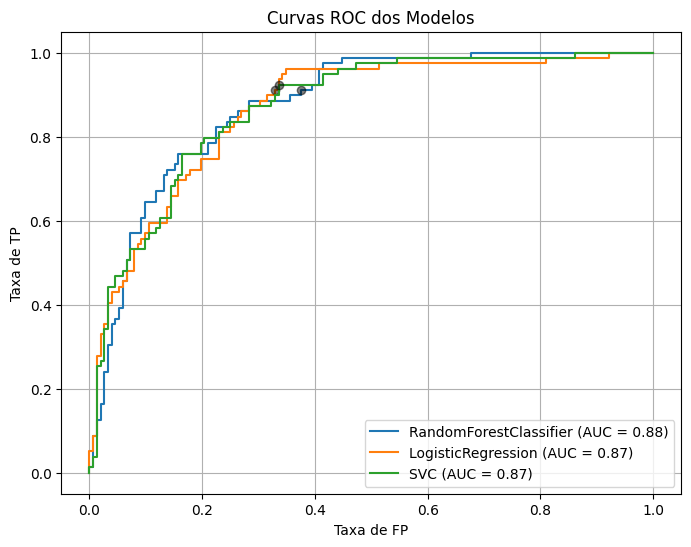

In [14]:
def plot_curvas_roc(modelos, y_test, confs, y_preds):
    '''
    Método que gera e faz plot das curvas ROC para vários classificadores.

    Args:
        - modelos - Lista dos modelos treinados (RandomForest, LogisticRegression, SVM).
        - y_test - Classificações do conjunto de teste.
        - confs - Lista com as matrizes de confusão para cada modelo.
        - y_preds - Lista das funções de decisão dos classificadores.
    '''
    plt.figure(figsize=(8, 6))

    for model, conf, y_pred_proba in zip(modelos, confs, y_preds):
        
        fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
        roc_auc = auc(fpr, tpr) # Calculo da AUC (área da curva ROC)

        TN, FP, FN, TP = conf.ravel()

        plt.plot(fpr, tpr, label=f"{model.__class__.__name__} (AUC = {roc_auc:.2f})")

        # marcação do limiar de decisão do modelo
        plt.plot(FP / (TN + FP), TP / (TP + FN), 'ok', alpha=0.5)

    plt.xlabel("Taxa de FP")
    plt.ylabel("Taxa de TP")
    plt.title("Curvas ROC dos Modelos")
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()

# Lista de modelos treinados
modelos = [rf, lr, svm]  
confs = [rf_calib_conf_matrix, lr_calib_conf_matrix, svm_calib_conf_matrix]
y_preds =[y_pred_rf, y_pred_lr, y_pred_svm]

plot_curvas_roc(modelos, yf, confs, y_preds)

## Normalização dos Dados com StandardScaler

A normalização dos dados dependendo do classificador pode ser uma processo crucial, pois ela ajusta as variáveis para que tenham uma distribuição com média 0 e variância 1. Isto ajuda a melhorar a performance de alguns algoritmos que são sensíveis à escala das variáveis.

Para normalizar os dados, inicialmente instânciou-se o ``StandardScaler``, de seguida fez-se os seguintes passos:

* **Ajuste e Transformação no Conjunto de Treino**: O scaler é ajustado aos dados de treino (``Xt``) usando o método ``fit_transform``. Este passo calcula a média e o desvio padrão das variáveis para que os dados de treino sejam escalados corretamente.

* **Transformação nos Conjuntos de Validação e Teste**: Após o ajuste do scaler nos dados de treino, os conjuntos de validação (``Xv``) e de teste (``Xf``) são transformados com o método ``transform``, sem que o scaler aprenda novamente, para garantir que a normalização seja consistente em todos os conjuntos.

In [15]:
standard_scaler = StandardScaler()

# Ajustar o scaler ao conjunto de treino e transformar
Xnt = standard_scaler.fit_transform(Xt)

# Transformar os conjuntos de validação e teste com o scaler ajustado no treino
Xnv = standard_scaler.transform(Xv)
Xnf = standard_scaler.transform(Xf)

# Verificação da média nula e variância unitária.
print("Média após normalização (treino):", np.round(np.abs(np.mean(Xnt, axis=0))))
print("Variância após normalização (treino):", np.var(Xnt, axis=0))

Média após normalização (treino): [0. 0. 0. 0. 0. 0. 0. 0.]
Variância após normalização (treino): [1. 1. 1. 1. 1. 1. 1. 1.]


## Escolha dos hiperparâmetros dos classificadores binários.

Após a normalização dos dados, voltou-se a fazer todos os procedimentos anteriores. Onde inicialmente fez-se uma nova escolha dos hiperparâmetros para cada um dos classificadores. 

Em cada um dos classificadores, não se modificou as opções dos hiperparâmetros, apenas utilizou-se os métodos feitos anteriormente ``rf_hiperparametros``, ``lr_hiperparametros`` e ``svm_hiperparametros``, onde se passaram os dados normalizados de ``Xnt`` (conjunto de treino normalizado) e ``Xnv`` (conjunto de validação normalizado), para assim ajustar cada classificador através da busca pelos melhores hiperparâmetros, obtendo assim o melhor desempenho para classificar os pacientes.

## Random Forest

In [16]:
n_estimators_options = [50, 100, 200]
max_depth_options = [None, 10, 20]
min_samples_split_options = [2, 5, 10]

best_params_rf_n, best_score_rf_n = rf_hiperparametros(n_estimators_options, max_depth_options, min_samples_split_options, Xnt, yt, Xnv, yv)

print("Melhores hiperparâmetros para Random Forest com base no score:", best_params_rf_n)
print("Score correspondente:", round(best_score_rf_n, 3))

Melhores hiperparâmetros para Random Forest com base no score: {'n_estimators': 200, 'max_depth': None, 'min_samples_split': 10}
Score correspondente: 0.817


## Logistic Regression

In [17]:
C_options = [0.01, 0.1, 1, 10, 100]
solver_options = ['lbfgs', 'liblinear']

best_params_lg_n, best_score_lg_n = lr_hiperparametros(C_options, solver_options, Xnt, yt, Xnv, yv)

print("Melhores hiperparâmetros para Logistic Regression com base no score:", best_params_lg_n)
print("Score correspondente:", round(best_score_lg_n, 3))

Melhores hiperparâmetros para Logistic Regression com base no score: {'C': 0.1, 'solver': 'lbfgs'}
Score correspondente: 0.804


## Support Vector Machine (SVM)

In [18]:
# Listas de valores de hiperparâmetros para testar
C_options = [0.1, 1, 10]
kernel_options = ['linear', 'rbf', 'sigmoid']
gamma_options = ['scale', 'auto']

best_params_svm_n, best_score_svm_n = svm_hiperparametros(C_options, kernel_options, gamma_options, Xnt, yt, Xnv, yv)

print("Melhores hiperparâmetros para SVM com base no score:", best_params_svm_n)
print("Score correspondente:", round(best_score_svm_n, 3))

Melhores hiperparâmetros para SVM com base no score: {'C': 10, 'kernel': 'linear', 'gamma': 'scale'}
Score correspondente: 0.81


## Avaliação dos Modelos e Comparação de Desempenho

Tal como foi feito para os dados não normalizados, após se descobrir os melhores hiperparâmetros para os três classificadores, instânciou-se os classificadores com os seus hiperparêmetros para assim estes serem treinados com o conjunto completo de treino (treino + validação), com dados normalizados, e testados com o conjunto de testes. <br>

Para juntar os conjuntos de treino e validação, utilizou-se o método ``np.concatenate``, onde junta-se ``Xnt`` com ``Xnv``. De seguida, utiliza-se o método ``evaluate_model`` para treinar os classificadores com ``Xn_treino`` e ``ytreino``, e testá-los com ``Xnf``.

(537, 8)
(537,)
Resultados para RandomForestClassifier:
Probabilidade total de acertos: 0.7965
Precisão: 0.7667
Recall: 0.5823
F-score: 0.6619
Matriz de Confusão:
[[138  14]
 [ 33  46]]

Resultados para LogisticRegression:
Probabilidade total de acertos: 0.7879
Precisão: 0.7778
Recall: 0.5316
F-score: 0.6316
Matriz de Confusão:
[[140  12]
 [ 37  42]]

Resultados para SVC:
Probabilidade total de acertos: 0.7792
Precisão: 0.7500
Recall: 0.5316
F-score: 0.6222
Matriz de Confusão:
[[138  14]
 [ 37  42]]



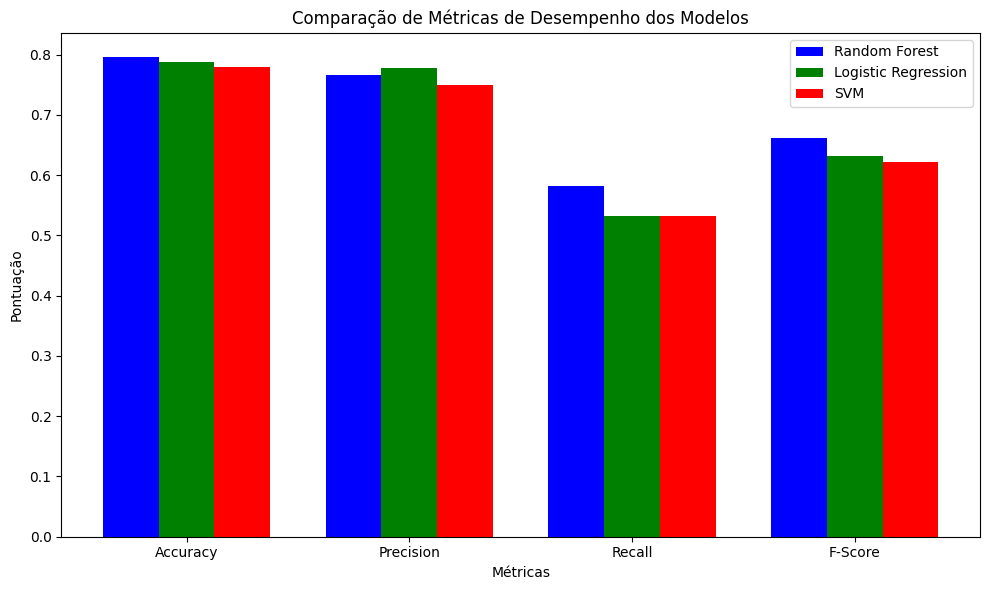

In [19]:
# Concatonou-se o conjunto de treino, com dados normalizados, Xnt, e o de
# validação, com dados normalizados, Xnv, para formar o conjunto de treino 
# completo Xn_treino.

Xn_treino = np.concatenate((Xnt, Xnv), axis=0)

# Prints para verificar a concatenação dos conjuntos
print(Xn_treino.shape)
print(ytreino.shape)

# Inicialização dos classificadores com os hiperparâmetros encontrados anteriormente
rf_n = RandomForestClassifier(n_estimators = best_params_rf_n['n_estimators'],
                             max_depth = best_params_rf_n['max_depth'], 
                             min_samples_split = best_params_rf_n['min_samples_split'], 
                             random_state=42)

lr_n = LogisticRegression(C=best_params_lg_n['C'], 
                        solver=best_params_lg_n['solver'], 
                        max_iter=1000, 
                        random_state=42)

svm_n = SVC(C=best_params_svm_n['C'], 
          kernel=best_params_svm_n['kernel'], 
          gamma=best_params_svm_n['gamma'], 
          random_state=42)


RandomForestResults_n, rf_conf_matrix = evaluate_model(rf_n, Xnf, yf, Xn_treino, ytreino)
LogisticRegressionResults_n, lg_conf_matrix = evaluate_model(lr_n, Xnf, yf, Xn_treino, ytreino)
SvmResults_n, svm_conf_matrix = evaluate_model(svm_n, Xnf, yf, Xn_treino, ytreino)

# Comparação gráfica dos resultados
bar_width = 0.25

plt.figure(figsize=(10, 6))
plt.bar(index, RandomForestResults_n, bar_width, label='Random Forest', color='blue')
plt.bar(index + bar_width, LogisticRegressionResults_n, bar_width, label='Logistic Regression', color='green')
plt.bar(index + 2 * bar_width, SvmResults_n, bar_width, label='SVM', color='red')

plt.xlabel('Métricas')
plt.ylabel('Pontuação')
plt.title('Comparação de Métricas de Desempenho dos Modelos')
plt.xticks(index + bar_width, metrics)
plt.legend()

plt.tight_layout()
plt.show()

> Comentário:

* **Random Forest** apresentou o melhor desempenho geral, com uma probabilidade total de acertos de 79.65%, uma boa precisão de 76.67% e recall de 58.23%. Embora tenha deixado de identificar alguns casos de diabetes, ele se destacou em comparação aos outros modelos.

* **Logistic Regression** teve um desempenho muito próximo ao do Random Forest, com uma probabilidade total de acertos um pouco menor de 78.79% e um recall mais baixo (53.16%). Sua precisão foi boa de 77.78%, sendo mais alta que a do Random Forest.

* **Support Vector Machine** teve o pior desempenho, com a menor probabilidade total de acertos de 77.92% e recall de 53.16%. Apesar de apresentar uma boa precisão (75%).

Em resumo, os três classificadores apresentaram resultados semelhantes, com o Random Forest sendo o modelo mais eficaz, enquanto a SVM teve o desempenho mais fraco. Tal como os classificadores com dados não normalizados e com apenas o treino com os seus hiperparâmetros, o recall dos classificadores está baixo, seguindo a lógica utilizada anteriormente (nos dados não normalizados). Estes classificadores terão de ser calibrados de maneira a aumentar o valor do recall, para assim melhorar a classificação dos pacientes com diabetes (diminuindo os falsos negativos).

--------------------------------------

## Calibração dos Modelos

Tal como  já foi referido anterioremente nos dados não normalizados, a calibração de um classificador é um processo importante quando se deseja ajustar o limiar de decisão. 

Utilizou-se o método ``limiar_modelo``, para determinar o melhor limiar de decisão, continuou-se com o raciocinio de tentar obter o limiar minimo que leve a um recall igual ou superior a 90%.

Após o calculo do limite de decisão, utilizou-se o método ``calibracao`` para assim aplicar o novo limiar de decisão aos seus respetivos modelos.

In [20]:
limiar_dos_modelos = 0.90

limiar_rf_n = limiar_modelo(rf_n, limiar_dos_modelos, Xnf, yf)
rf_calib_results_n, rf_n_calib_conf_matrix, y_pred_rf_n = calibracao(rf_n, Xnf, yf, limiar_rf_n)

limiar_lr_n = limiar_modelo(lr_n, limiar_dos_modelos, Xnf, yf)
lr_calib_results_n, lr_n_calib_conf_matrix, y_pred_lr_n = calibracao(lr_n, Xnf, yf, limiar_lr_n)

limiar_svm_n = limiar_modelo(svm_n, limiar_dos_modelos, Xnf, yf)
svm_calib_results_n, svm_n_calib_conf_matrix, y_pred_svm_n = calibracao(svm_n, Xnf, yf, limiar_svm_n)

Resultados para RandomForestClassifier, com o limiar 0.25818617697661805:
Probabilidade total de acertos: 0.7229
Precisão: 0.5581
Recall: 0.9114
F-score: 0.6923
Matriz de Confusão:
[[95 57]
 [ 7 72]]

Resultados para LogisticRegression, com o limiar 0.2672417017379746:
Probabilidade total de acertos: 0.7619
Precisão: 0.5984
Recall: 0.9241
F-score: 0.7264
Matriz de Confusão:
[[103  49]
 [  6  73]]

Resultados para SVC, com o limiar -0.9806093475331799:
Probabilidade total de acertos: 0.7532
Precisão: 0.5902
Recall: 0.9114
F-score: 0.7164
Matriz de Confusão:
[[102  50]
 [  7  72]]



> Comentário:

* **Random Forest** teve o pior desempenho, com uma probabilidade total de acertos de 72.29% e precisão de 55.81%, no entanto, ele teve um ótimo recall de 91.14%. Esse alto recall indica que o modelo foi muito eficaz em classificar os casos de pacientes com diabetes, mas entre os três classificadores ele foi aquele com maior número de falsos alarmes.

* **Logistic Regression** apresentou o melhor desempenho geral, com a melhor probabilidade total de acertos de 76.19% e com o melhor recall de 92.41%. A precisão deste desceu para 59.84%, sendo esta a melhor entre os três classificadores. Este classificador também teve o f-score mais alto de 72.64% demonstrando ser o modelo mais balanceado dos três, após a calibração.

* **Support Vector Machine** teve um desempenho muito próximo ao do Logistic Regression, com uma probabilidade total de acertos de 75.32% e um recall igual ao do Random Forest de 91.14%. Com o aumento do recall a sua precisão desceu para 59.02%. 

Em resumo, os três classificadores apresentaram resultados semelhantes nas métricas de desempenho, com o Random Forest sendo o modelo com os piores valores, enquanto a Logistic Regression com os melhores. A Logistic Regression teve o melhor recall, o que é crucial em contextos médicos, pois indica que mais casos de pacientes com diabetes foram corretamente identificados.

----------------------------------------------------------------

## Visualização das Curvas ROC dos modelos calibrados

Após a calibração dos modelos e sua análise, decidiu-se visualizar as suas curvas ROC. <br>
Utilizou-se o método ``plot_curvas_roc`` para visualizar esssas curvas, e verificar as conclusões retiradas nos processos de calibração dos modelos, onde concluiu-se priorizar o aumento do recall (através da diminuição da falha de deteção dos pacientes com diabetes).

Com o ``plot`` das várias curvas ROC, também é possivel confirmar a semelhança entre os vários modelos, que após a busca dos hiperparâmetros e a sua calibração apresentam limiares de decisão parecidos e curvas de ROC, o que era esperado, pois com o cálculo das várias métricas de desempenho todos os modelos apresentaram semelhanças nos seus valores.

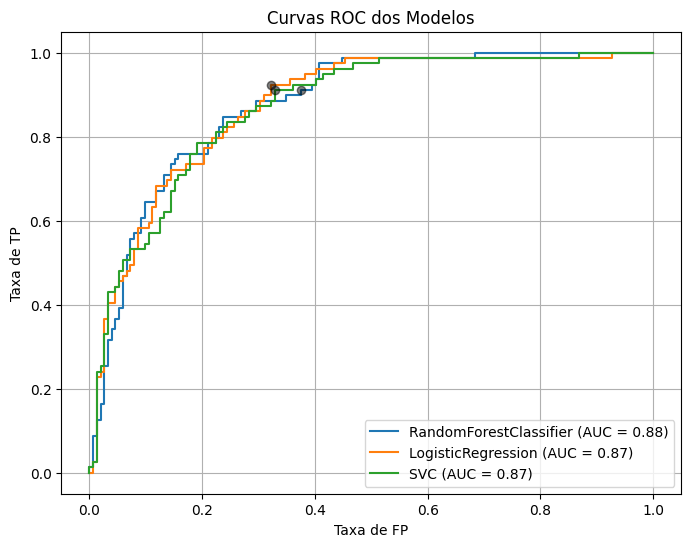

In [21]:
# Lista de modelos treinados
modelos = [rf_n, lr_n, svm_n]  
confs = [rf_n_calib_conf_matrix, lr_n_calib_conf_matrix, svm_n_calib_conf_matrix]
y_preds =[y_pred_rf_n, y_pred_lr_n, y_pred_svm_n]

plot_curvas_roc(modelos, yf, confs, y_preds)

## Comparação Gráfica: Modelos com e sem Normalização

O código abaixo tem como objetivo a comparação do desempenho dos modelos (Random Forest, Logistic Regression e SVM) quando treinados com dados não normalizados e dados normalizados. A normalização é realizada com o StandardScaler para ajustar as variáveis a uma distribuição com média nula e variância unitária.

Acomparação é feita através de um gráfico de barras, onde se utilizou o método ``barras`` para gerar os gráficos, onde se compara para cada modelo com dados não normalizados e normalizados as suas métricas de desempenho após a calibração dos modelos (probabilidade total de acertos, precisão, recall e f-Score).

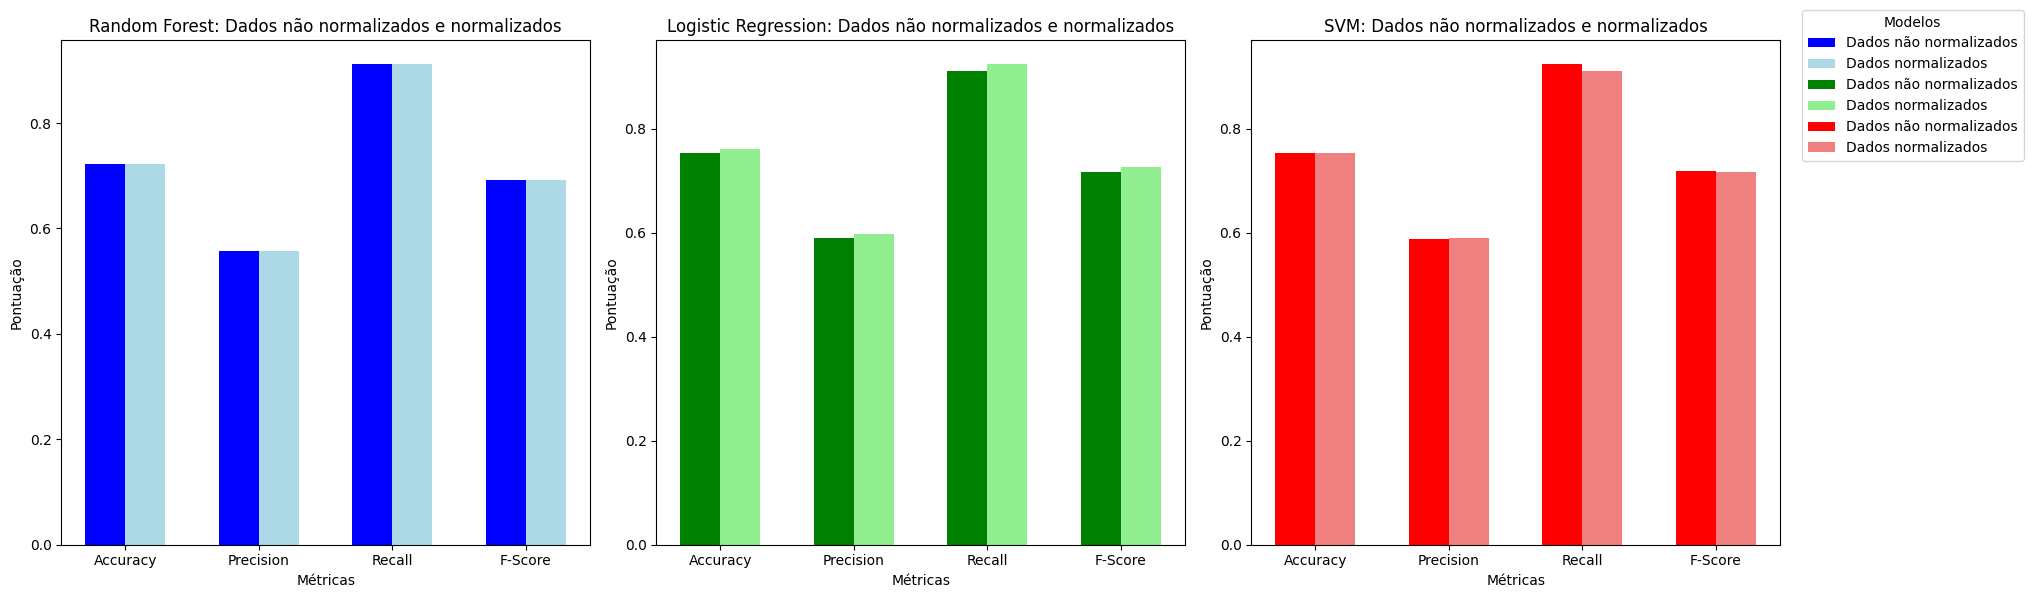

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
bar_width = 0.3

title1='Random Forest: Dados não normalizados e normalizados'
label1 = 'Dados não normalizados'
label2 = 'Dados normalizados'

bars_rf, bars_rf_n = barras(axes[0], title1, index, bar_width, metrics,rf_calib_results, rf_calib_results_n, label1, label2, 'blue', 'lightblue')

title1='Logistic Regression: Dados não normalizados e normalizados'
bars_lr, bars_lr_n = barras(axes[1], title1, index, bar_width, metrics,lr_calib_results, lr_calib_results_n, label1, label2, 'green', 'lightgreen')

title1='SVM: Dados não normalizados e normalizados'
bars_svm, bars_svm_n = barras(axes[2], title1, index, bar_width, metrics,svm_calib_results, svm_calib_results_n, label1, label2, 'red', 'lightcoral')

plt.tight_layout() # Para evitar sobreposição entre os subplots

# Posição da legenda para fora dos gráficos
fig.legend(
    handles=[bars_rf, bars_rf_n, bars_lr, bars_lr_n, bars_svm, bars_svm_n],
    loc='upper left',
    bbox_to_anchor=(1, 1), # Posição da legenda fora do gráfico
    title="Modelos"
)

plt.show()

> Comentário:

* **Random Forest:** O desempenho com dados normalizados e não normalizados, são idênticos. Isto já era esperado, pois este classificador, devido à forma como constrói as árvores de decisão, é insensível à escala das variáveis dos dados.

* **Logistic Regression:** Ao comparar as métricas de desempenho, é possivel verificar uma pequena melhoria em todas as métricas com dados normalizados. Isto já era esperado, visto que este modelo é sensível à escala dos dados. <br>
Normalizar os dados garante que todas as variáveis estejam na mesma escala, permitindo valores comparáveis em magnitude. Isto facilita o processo de otimização do classificador, pois o modelo consegue explorar melhor os padrões dos dados e definir um limiar de decisão mais eficiente.

* **Support Vector Machine:** Ao comparar as métricas de desempenho, é possivel verificar que estas são semelhantes, com pequenas diferenças, a probabilidade total de acertos é a mesma (75.32%), os dados normalizados têm melhor precisão (59.02%), no entanto os dados não normalizados têm melhor recall (92.41%) e melhor f-score (71.92%). <br>
Por norma, este modelo é sensível à escala dos dados, no entanto, isto não se demonstra no nosso caso devido aos diferentes valores de C. O valor de C para os dados normalizados foi ajustado para 10, permitindo um ajuste mais flexível, enquanto para os dados não normalizados, o valor foi 1, resultando em maior regularização. Esta diferença no valor de C reflete como o modelo ajusta a sua complexidade em função á escala dos dados, mas, de forma geral, os resultados continuam bastante próximos, sugerindo que o modelo foi capaz de se adaptar bem a ambas as condições.

A análise dos resultados revelou que a normalização tem impacto variável entre os modelos. O Random Forest não apresentou alteração no seu desempenho, pois é insensível à escala dos dados. Já a Logistic Regression beneficiou-se da normalização, mostrando uma melhoria em todas as suas métricas, já que este modelo é sensível à escala. No caso do Support Vector Machine, as métricas foram semelhantes, mas o ajuste no valor de C, dependente da escala, refletiu em ligeiras diferenças. Em resumo, a normalização é mais relevante para modelos como Logistic Regression e SVM, enquanto para Random Forest, não há diferença significativa.

----------------------------------------------------------------

## Conclusão

Através deste projeto, foi possível analisar e comparar o desempenho de três classificadores binários (Random Forest, Logistic Regression e Support Vector Machine) no diagnóstico de diabetes, utilizando dados do National Institute of Diabetes and Digestive and Kidney Diseases. <br>

A normalização dos dados teve um impacto significativo na Logistic Regression, melhorando as suas métricas de desempenho, pois este modelo é sensível à escala dos dados. No caso do Random Forest, os resultados foram idênticos para dados normalizados e não normalizados, uma vez que este modelo não é sensível à escala dos dados. Já o Support Vector Machine mostrou resultados semelhantes em ambas as situações, com pequenas diferenças nas métricas de precisão e recall, que foram influenciadas pela escolha do parâmetro C, ajustado de forma diferente para os dados normalizados e não normalizados. <br>

Em geral, a análise reforça a importância da preparação adequada dos dados, especialmente para modelos que dependem da escala. Isto destaca a robustez do Random Forest, visto que não é sensível à escala das variáveis dos dados. O projeto também evidenciou a necessidade de selecionar os hiperparâmetros adequados para cada modelo e a sua respetiva calibração, com o objetivo de maximizar o recall na classificação de pacientes com diabetes, especialmente em um contexto médico em que minimizar falsos negativos é crucial.

## Bibliografia 

### Consulta:

Marques, Gonçalo. (2024 - 2025). Aprendizagem Automática - Moodle

SVC. (2024). Scikit-Learn. https://scikit-learn.org/dev/modules/generated/sklearn.svm.SVC.html

‌LogisticRegression. (2024). Scikit-Learn. https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html

‌RandomForestClassifier. (2024). Scikit-Learn. https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.RandomForestClassifier.html
